# Folds in Fair Bin's stump tally: MRE and time

As `kfold_stump.py --method fairbin_zbonf` (unbounded Fair Bin, k = 10). The stump's out-of-fold predictions use 2,
3, 4, 5, 7 or 10 folds; **folds = 1** is a single stratified 50/50 holdout instead, where the stump fits one half
and only the other half's errors are counted. The bins are scored with a random forest on the test rows
(`metrics.evaluate`).

**Tally time** is the median of 3 repeats when one run takes under 0.5 s (`timing_bench.timed`), after an untimed
warm-up. Folds run in a shuffled order per (dataset, seed). Timings depend on the machine and its load; MRE does
not.

Writes `figures/folds_mre.png` and `figures/folds_time.png`. **Run time:** about an hour on all 15 datasets.
Set `DATASETS` to a subset to try it.

In [1]:
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import datasets, fairbin, figures, metrics

OUT = ROOT / "figures"
OUT.mkdir(exist_ok=True)
SEEDS = [92, 50, 61, 19, 11, 8, 2, 51, 70]  # the paper's nine eval seeds
DATASETS = datasets.group_names("uci")      # the 15 UCI datasets
K = 10
FOLDS = (1, 2, 3, 4, 5, 7, 10)
REPEAT_BELOW_S = 0.5

## Tally and timing helpers
`holdout_predictions` (from `kfold_stump.py`) and `timed` (from `timing_bench.py`), copied.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


def holdout_predictions(train, y_name, seed):
    """Single stratified 50/50 split of `train`: the stump fits one half, predicts the other (index -> pred)."""
    y = train[y_name]
    strat = y if y.value_counts().min() >= 2 else None
    fit, held = train_test_split(train.index, test_size=0.5, random_state=seed, stratify=strat)
    model = DecisionTreeClassifier(max_depth=1, random_state=seed).fit(train.loc[fit].drop(columns=[y_name]), y.loc[fit])
    return pd.Series(model.predict(train.loc[held].drop(columns=[y_name])), index=held)


def stump_predictions(train, y_name, seed, folds):
    """Out-of-fold stump prediction per training row (folds >= 2), or the 50/50 holdout (folds = 1)."""
    if folds == 1:
        return holdout_predictions(train, y_name, seed)
    pred = fairbin.oof_predictions(train.drop(columns=[y_name]), train[y_name], seed, folds=folds)
    return pd.Series(pred, index=train.index)


def timed(fn):
    """Wall time of fn(); calls under REPEAT_BELOW_S are repeated 3 times, median kept."""
    t0 = time.perf_counter()
    fn()
    first = time.perf_counter() - t0
    if first >= REPEAT_BELOW_S:
        return first, 1
    times = [first]
    for _ in range(2):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times)), 3


def score(data, spec, n_classes, seed, cuts, cache):
    """metrics.evaluate (rf) on cuts, each distinct cut vector once per (dataset, seed)."""
    key = tuple(cuts)
    if key not in cache:
        binned = fairbin.apply_bins(data[spec.bin_col], cuts).to_numpy(float)
        bin_idx, layout = metrics.bin_layout(binned, cuts)
        ev = metrics.evaluate(data, spec.bin_col, spec.target, binned, bin_idx, len(cuts) - 1, "rf", seed, n_classes == 2)
        cache[key] = {"mre": ev["mre"], "accuracy": ev["accuracy"], "smallest_bin_share": layout["smallest_bin_share"]}
    return cache[key]

## Run

In [3]:
# untimed warm-up: the first tally of a session otherwise waits on first-use loading
rng = np.random.default_rng(0)
toy = pd.DataFrame({"x": rng.normal(size=500), "age": rng.integers(18, 80, 500), "y": rng.integers(0, 2, 500)})
for f in (1, 2):
    stump_predictions(toy, "y", 0, f)

out = []
start = time.perf_counter()
for ds in DATASETS:
    data, spec, n_classes = datasets.load(ds)
    for seed in SEEDS:
        train = data.loc[metrics.split(data, spec.target, seed)[0].index]
        col, y = train[spec.bin_col], train[spec.target]
        order = list(FOLDS)
        random.Random(seed).shuffle(order)
        cache = {}
        for f in order:
            holder = {}
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                secs, reps = timed(lambda: holder.update(pred=stump_predictions(train, spec.target, seed, f)))
            used = holder["pred"].index  # the held-out half for folds = 1, every training row otherwise
            values, errors, rows = fairbin.error_counts(col.loc[used], y.loc[used], holder["pred"].to_numpy())
            cuts = fairbin.choose_cuts(values, errors, rows, K, fairbin.bonferroni_z(len(values)))[1]
            out.append({"dataset": ds, "folds": f, "eval_seed": seed, "tally_time_s": secs, "tally_reps": reps,
                        "bin_cuts": cuts, **score(data, spec, n_classes, seed, cuts, cache)})
    print(f"[{(time.perf_counter() - start) / 60:5.1f}m] {ds} done", flush=True)
runs = pd.DataFrame(out)

[  0.4m] uci863_maternal done
[  1.2m] uci503_hcv done
[  1.5m] uci30_contraceptive done
[  2.3m] uci579_myocardial done
[  3.3m] uci544_obesity done
[  3.8m] uci890_aids done
[  4.2m] uci887_nhanes done
[  5.4m] uci272_skillcraft done
[  6.4m] uci697_dropout done
[  7.8m] uci852_gendergap done
[  8.8m] uci350_credit done
[ 10.0m] uci222_bank done
[ 11.7m] uci2_adult done
[ 12.8m] uci827_sepsis done
[ 23.8m] uci117_kdd done


## Summary
Mean MRE (%) over datasets and median tally time (s) summed over datasets, per number of folds.

In [4]:
pd.DataFrame({"mre_pct": 100 * runs.groupby("folds").mre.mean(),
              "tally_time_s_sum_of_medians": runs.groupby(["dataset", "folds"]).tally_time_s.median().groupby("folds").sum()}).round(2)

,mre_pct,tally_time_s_sum_of_medians
folds,,
1,31.26,1.42
2,30.70,2.11
3,30.66,3.27
4,30.67,4.47
5,30.50,5.61
7,30.66,8.14
10,30.62,11.40


## Figures

/Users/samika/BinStability/repo/figures/folds_mre.png
/Users/samika/BinStability/repo/figures/folds_time.png


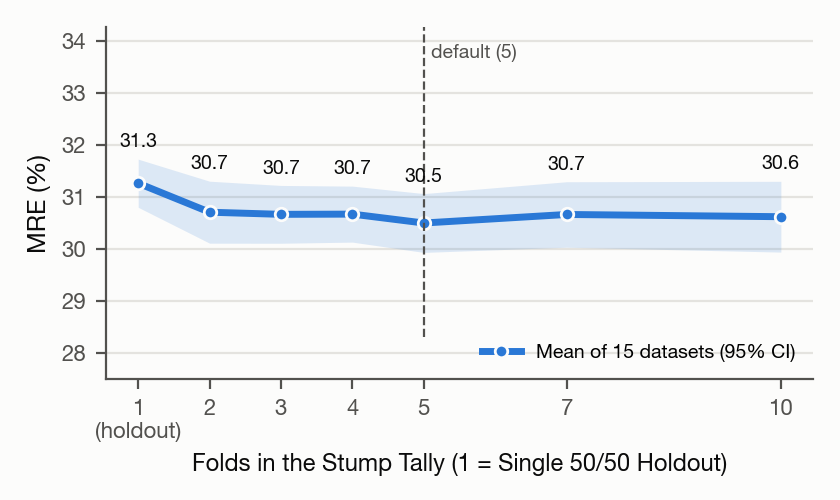

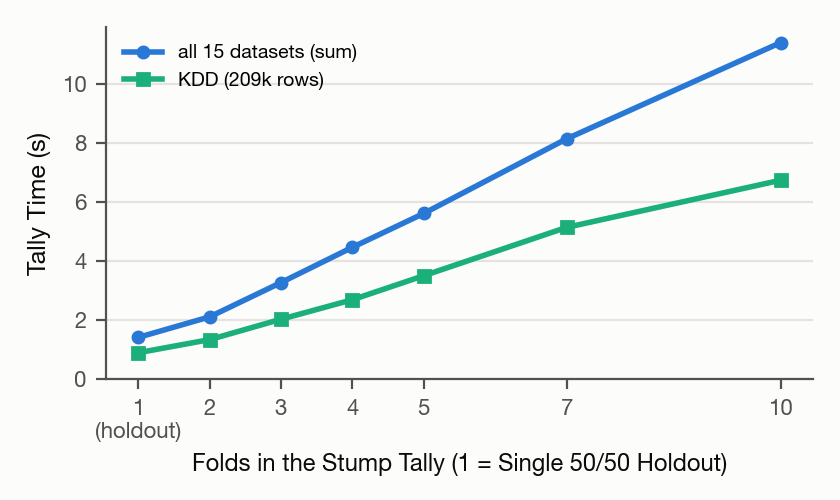

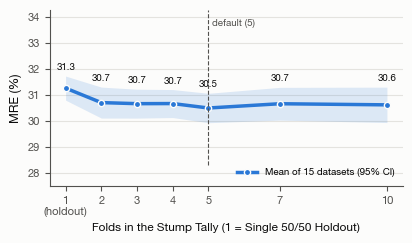

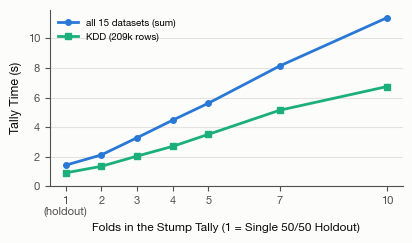

In [7]:
import importlib
importlib.reload(figures)                     # pick up the fixed figures.folds
runs["status"] = "ok"                         # works with the old copy too, if the reload didn't take

figures.pf_style()
figures.folds(runs, OUT)
for name in ("folds_mre", "folds_time"):
    display(Image(str(OUT / f"{name}.png")))
